# ECE 473 — Milestone I: Prediction markets × Bluesky × GDELT (NBA pilot)

This notebook runs the Milestone I pipeline end to end and shows the preliminary analysis.

**Data sources (all real, no credentials needed):**
* Polymarket Gamma / CLOB / Data APIs: market metadata, hourly prices, trades
* Bluesky `app.bsky.feed.searchPosts` via `api.bsky.app`: hourly post counts per team
* GDELT 2.0 raw GKG 15-minute files: hourly news-article counts per team

The project folder ships with the raw API responses cached in `data/raw/`, so a rerun reproduces the
exact results offline. Deleting `data/raw/` makes the pipeline re-download everything (about 30–40 minutes).

## 1. Setup
**In Google Colab:** upload `ece473-pm-social.zip` with the file panel on the left (📁 → upload icon), then run the next cell.
Alternatively, copy the folder to Google Drive under `MyDrive/ece473-pm-social` and the cell will find it.
Run locally, the cell uses the folder containing this notebook.

In [1]:
import os, sys, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if Path("/content/ece473-pm-social.zip").exists():
        zipfile.ZipFile("/content/ece473-pm-social.zip").extractall("/content")
        PROJECT = Path("/content/ece473-pm-social")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT = Path("/content/drive/MyDrive/ece473-pm-social")
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

assert (PROJECT / "src" / "pmsocial").exists(), f"project folder not found at {PROJECT}"
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))
print("project:", PROJECT)

project: /Users/aliciacheng/Desktop/ece473-pm-social


In [2]:
if IN_COLAB:
    %pip install -q -r requirements.txt

## 2. Run the pipeline
Stages: `select → polymarket → bluesky → gdelt → merge → analyze`. Cached responses are reused.

In [3]:
import subprocess
r = subprocess.run([sys.executable, "scripts/run_pipeline.py", "--all"], capture_output=True, text=True)
print(r.stdout[-6000:]); print(r.stderr[-3000:])
assert r.returncode == 0, "pipeline failed - see stderr above"

-mil-2026-10-23', 'n_price_home': 142, 'n_price_away': 147, 'n_trades': 881, 'max_abs_sum_dev': 0.0, 'trades_wrong_market': 0, 'trades_unknown_asset': 0, 'trades_after_start': 0, 'earliest_trade': Timestamp('2026-10-20 21:28:36+0000', tz='UTC'), 'n_pregame_hours': 164, 'n_pregame_price_hours': 140, 'n_pregame_trades': 881}
{'slug': 'nba-cha-bkn-2026-10-21', 'n_price_home': 154, 'n_price_away': 153, 'n_trades': 1174, 'max_abs_sum_dev': 0.0, 'trades_wrong_market': 0, 'trades_unknown_asset': 0, 'trades_after_start': 0, 'earliest_trade': Timestamp('2026-10-15 01:07:17+0000', tz='UTC'), 'n_pregame_hours': 167, 'n_pregame_price_hours': 154, 'n_pregame_trades': 1174}
{'slug': 'nba-nyk-bos-2026-10-23', 'n_price_home': 144, 'n_price_away': 144, 'n_trades': 1205, 'max_abs_sum_dev': 0.0, 'trades_wrong_market': 0, 'trades_unknown_asset': 0, 'trades_after_start': 0, 'earliest_trade': Timestamp('2026-10-17 11:17:18+0000', tz='UTC'), 'n_pregame_hours': 167, 'n_pregame_price_hours': 142, 'n_pregame_tr

## 3. Selected markets

In [4]:
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
P = PROJECT / "data" / "processed"
markets = pd.read_csv(P / "markets.csv")
markets[markets.selected][["slug","event_id","market_id","condition_id","away","home","game_start_utc",
                            "market_created_utc","volume","n_pregame_price_points"]]

,slug,event_id,market_id,condition_id,away,home,game_start_utc,market_created_utc,volume,n_pregame_price_points
0,nba-cle-phi-2026-10-22,1197295,5765055,0xfa657d6b58e1b7cb79969d206b46093a17d6b16b8789...,cle,phi,2026-10-22 23:00:00+00:00,2026-10-16 00:51:04.727555+00:00,8.251638e+06,143.0
1,nba-mem-uta-2026-10-26,1222277,5962889,0x401c1614a93ddc098c97338b5452d887f4ca1617a444...,mem,uta,2026-10-27 01:00:00+00:00,2026-10-20 06:51:06.357589+00:00,5.558583e+06,136.0
2,nba-den-okc-2026-10-22,1198445,5769220,0x3adb3ca4a12b16d8081e6458dbf4fbe13a33e873eedc...,den,okc,2026-10-23 01:30:00+00:00,2026-10-16 06:51:04.153156+00:00,5.113707e+06,140.0
7,nba-chi-mil-2026-10-23,1202606,5792081,0xd8aee6582edee17dfc5b1743699569a4a81d4ed8385b...,chi,mil,2026-10-23 20:00:00+00:00,2026-10-17 00:51:10.626398+00:00,3.999588e+06,140.0
8,nba-cha-bkn-2026-10-21,1191464,5716444,0x12c0ff4a99b3f160c77b10c8e9ab08a858bd00270de1...,cha,bkn,2026-10-21 23:30:00+00:00,2026-10-15 00:51:09.351715+00:00,3.836643e+06,154.0
9,nba-nyk-bos-2026-10-23,1202600,5792063,0xfef153ff34d43a4462ca8a20313ed3b117698adf90b6...,nyk,bos,2026-10-23 23:00:00+00:00,2026-10-17 00:51:03.936549+00:00,3.801132e+06,142.0
12,nba-tor-min-2026-10-25,1215092,5911664,0x4d3b279606d656c8cd73a837293acdf65fe675ddf910...,tor,min,2026-10-25 23:00:00+00:00,2026-10-19 00:51:08.257635+00:00,3.335625e+06,140.0
14,nba-hou-sas-2026-10-23,1203772,5797980,0x42dc8b594c965f0fa5042eed05071bab1bf4d863379b...,hou,sas,2026-10-24 01:30:00+00:00,2026-10-17 06:51:06.299200+00:00,3.170670e+06,138.0


In [5]:
print("Excluded candidates by reason:")
markets[~markets.selected].exclusion.value_counts()

Excluded candidates by reason:


exclusion
not needed (sample full)    34
team already in sample       7
Name: count, dtype: int64

In [6]:
pd.read_csv(P / "polymarket_checks.csv")

,slug,n_price_home,n_price_away,n_trades,max_abs_sum_dev,trades_wrong_market,trades_unknown_asset,trades_after_start,earliest_trade,n_pregame_hours,n_pregame_price_hours,n_pregame_trades
0,nba-cle-phi-2026-10-22,146,152,2207,0.000,0,0,0,2026-10-18 07:13:32+00:00,167,143,2207
1,nba-mem-uta-2026-10-26,138,138,1036,0.000,0,0,0,2026-10-21 02:45:36+00:00,163,136,1036
2,nba-den-okc-2026-10-22,143,149,1218,0.000,0,0,0,2026-10-17 16:00:12+00:00,163,140,1218
3,nba-chi-mil-2026-10-23,142,147,881,0.000,0,0,0,2026-10-20 21:28:36+00:00,164,140,881
4,nba-cha-bkn-2026-10-21,154,153,1174,0.000,0,0,0,2026-10-15 01:07:17+00:00,167,154,1174
5,nba-nyk-bos-2026-10-23,144,144,1205,0.000,0,0,0,2026-10-17 11:17:18+00:00,167,142,1205
6,nba-tor-min-2026-10-25,141,139,1805,0.005,0,0,0,2026-10-21 02:04:53+00:00,167,140,1805
7,nba-hou-sas-2026-10-23,140,139,671,0.000,0,0,0,2026-10-18 15:00:09+00:00,163,138,671


## 4. Merged panel and validation checks

In [7]:
import json
panel = pd.read_parquet(P / "panel.parquet")
print(json.dumps(json.loads((P / "panel_checks.json").read_text()), indent=2))
panel.head()

{
  "rows": 1321,
  "games": 8,
  "duplicate_game_hours": 0,
  "rows_ending_after_start": 0,
  "targets_ending_after_start": 0,
  "non_hourly_gaps": 0,
  "tz_is_utc": true,
  "missing_by_column": {
    "p_home_obs": 188,
    "p_home": 8,
    "dp": 16,
    "abs_dp": 16,
    "abs_dp_lag1": 24,
    "log_vol_lag1": 8,
    "abs_dp_next": 16,
    "log_vol_next": 8
  }
}


,slug,condition_id,hour,p_home_obs,price_observed,p_home,n_trades,volume_usd,home,away,game_start_utc,hours_to_game,bsky_posts_home,bsky_abn_home,bsky_status_home,...,bsky_status_away,gdelt_away,dp,abs_dp,log_vol,abs_dp_lag1,log_vol_lag1,bsky_posts_total,log_bsky_total,bsky_abn_mean,gdelt_total,log_gdelt_total,abs_dp_next,log_vol_next,target_hour
0,nba-cle-phi-2026-10-22,0xfa657d6b58e1b7cb79969d206b46093a17d6b16b8789...,2026-10-16 00:00:00+00:00,NaN,False,NaN,0.0,0.0,phi,cle,2026-10-22 23:00:00+00:00,166.0,1.0,-0.467299,ok,...,ok,2.0,NaN,NaN,0.0,NaN,NaN,1.0,0.693147,-0.619935,6.0,1.945910,NaN,0.0,2026-10-16 01:00:00+00:00
1,nba-cle-phi-2026-10-22,0xfa657d6b58e1b7cb79969d206b46093a17d6b16b8789...,2026-10-16 01:00:00+00:00,0.59,True,0.59,0.0,0.0,phi,cle,2026-10-22 23:00:00+00:00,165.0,0.0,-1.170074,ok,...,ok,2.0,NaN,NaN,0.0,NaN,0.0,0.0,0.000000,-0.963693,3.0,1.386294,0.000,0.0,2026-10-16 02:00:00+00:00
2,nba-cle-phi-2026-10-22,0xfa657d6b58e1b7cb79969d206b46093a17d6b16b8789...,2026-10-16 02:00:00+00:00,0.59,True,0.59,0.0,0.0,phi,cle,2026-10-22 23:00:00+00:00,164.0,1.0,-0.461668,ok,...,ok,1.0,0.0,0.0,0.0,NaN,0.0,1.0,0.693147,-0.598313,1.0,0.693147,0.000,0.0,2026-10-16 03:00:00+00:00
3,nba-cle-phi-2026-10-22,0xfa657d6b58e1b7cb79969d206b46093a17d6b16b8789...,2026-10-16 03:00:00+00:00,0.59,True,0.59,0.0,0.0,phi,cle,2026-10-22 23:00:00+00:00,163.0,3.0,0.231479,ok,...,ok,1.0,0.0,0.0,0.0,0.0,0.0,5.0,1.791759,0.297567,1.0,0.693147,0.000,0.0,2026-10-16 04:00:00+00:00
4,nba-cle-phi-2026-10-22,0xfa657d6b58e1b7cb79969d206b46093a17d6b16b8789...,2026-10-16 04:00:00+00:00,0.59,True,0.59,0.0,0.0,phi,cle,2026-10-22 23:00:00+00:00,162.0,2.0,-0.060198,ok,...,ok,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.098612,-0.400394,0.0,0.000000,0.015,0.0,2026-10-16 05:00:00+00:00


In [8]:
pd.read_csv(P / "descriptive_stats.csv", index_col=0)

,count,mean,std,min,50%,90%,max
home win prob,1313.0,0.5833,0.0770,0.445,0.56,0.7100,7.450000e-01
|Δp| per hour,1305.0,0.0022,0.0067,0.000,0.00,0.0100,9.500000e-02
trades / hour,1321.0,7.4852,32.3728,0.000,0.00,18.0000,7.080000e+02
USDC volume / hour,1321.0,4790.7084,53877.1296,0.000,0.00,1959.5329,1.377216e+06
Bluesky posts/h (home),1321.0,4.3906,11.2619,0.000,1.00,10.0000,1.840000e+02
Bluesky posts/h (away),1321.0,6.7986,19.4793,0.000,2.00,14.0000,4.950000e+02
GDELT articles/h (home),1321.0,4.2612,7.0175,0.000,2.00,10.0000,5.300000e+01
GDELT articles/h (away),1321.0,4.0151,7.1303,0.000,2.00,10.0000,5.900000e+01


## 5. Figures

fig1_market_probability.png


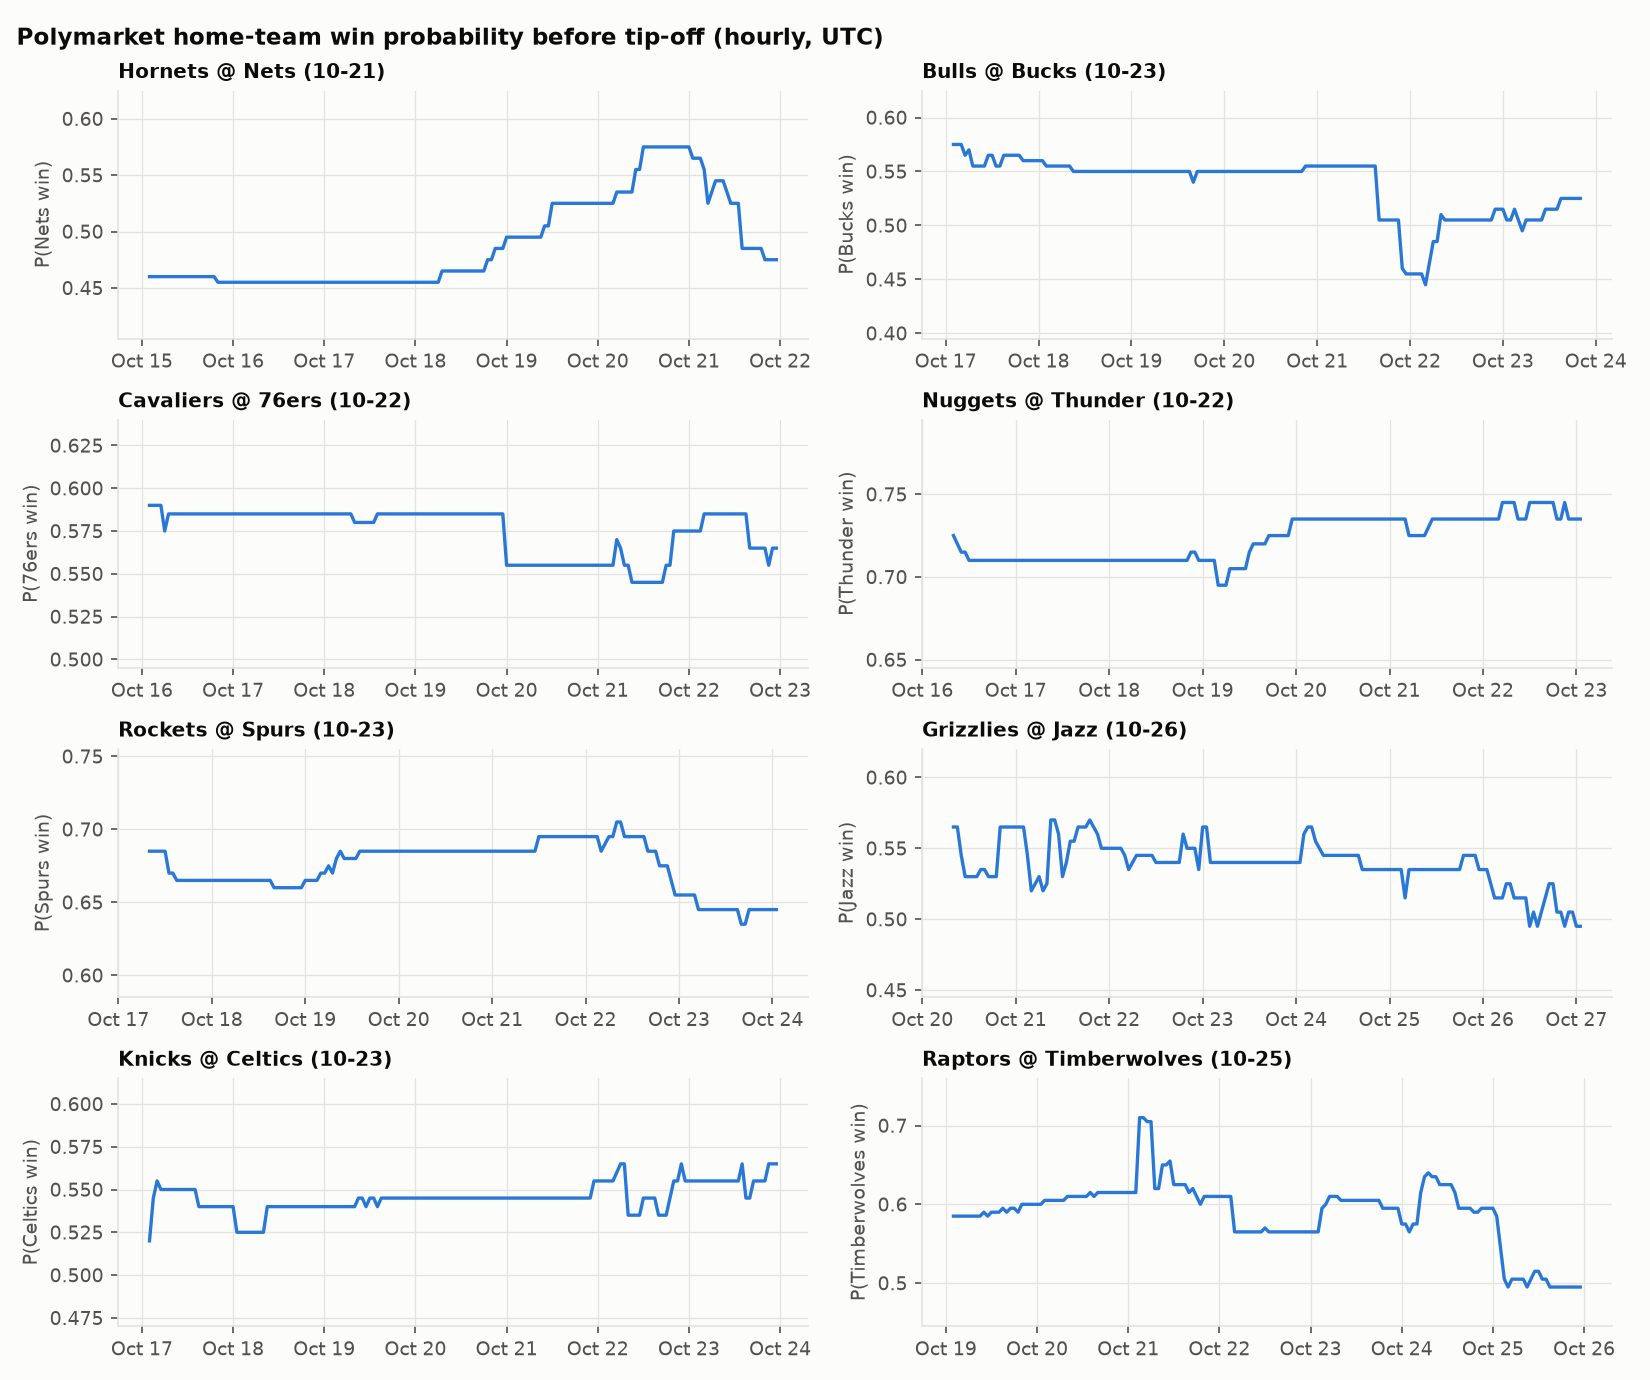

fig2_bluesky_attention.png


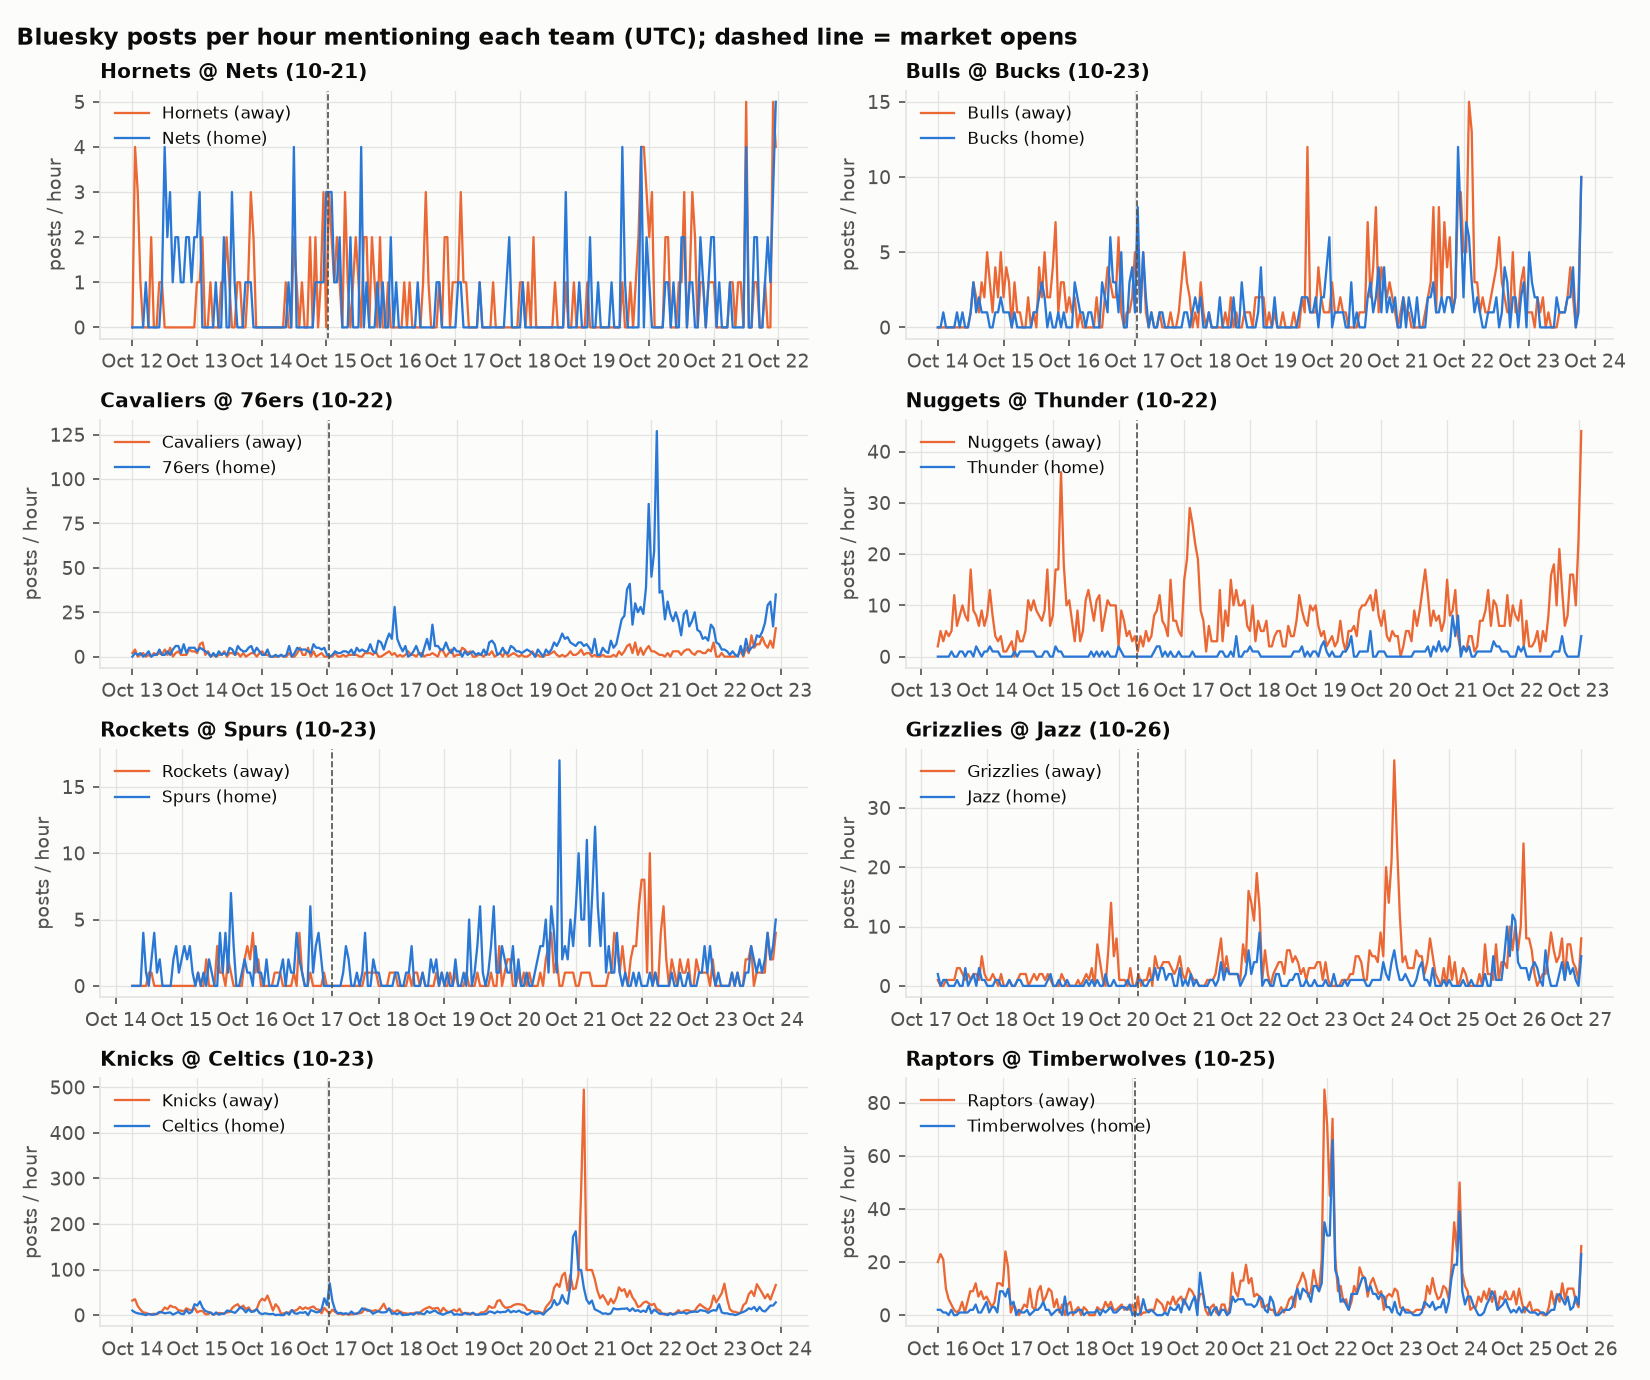

fig3_gdelt_news.png


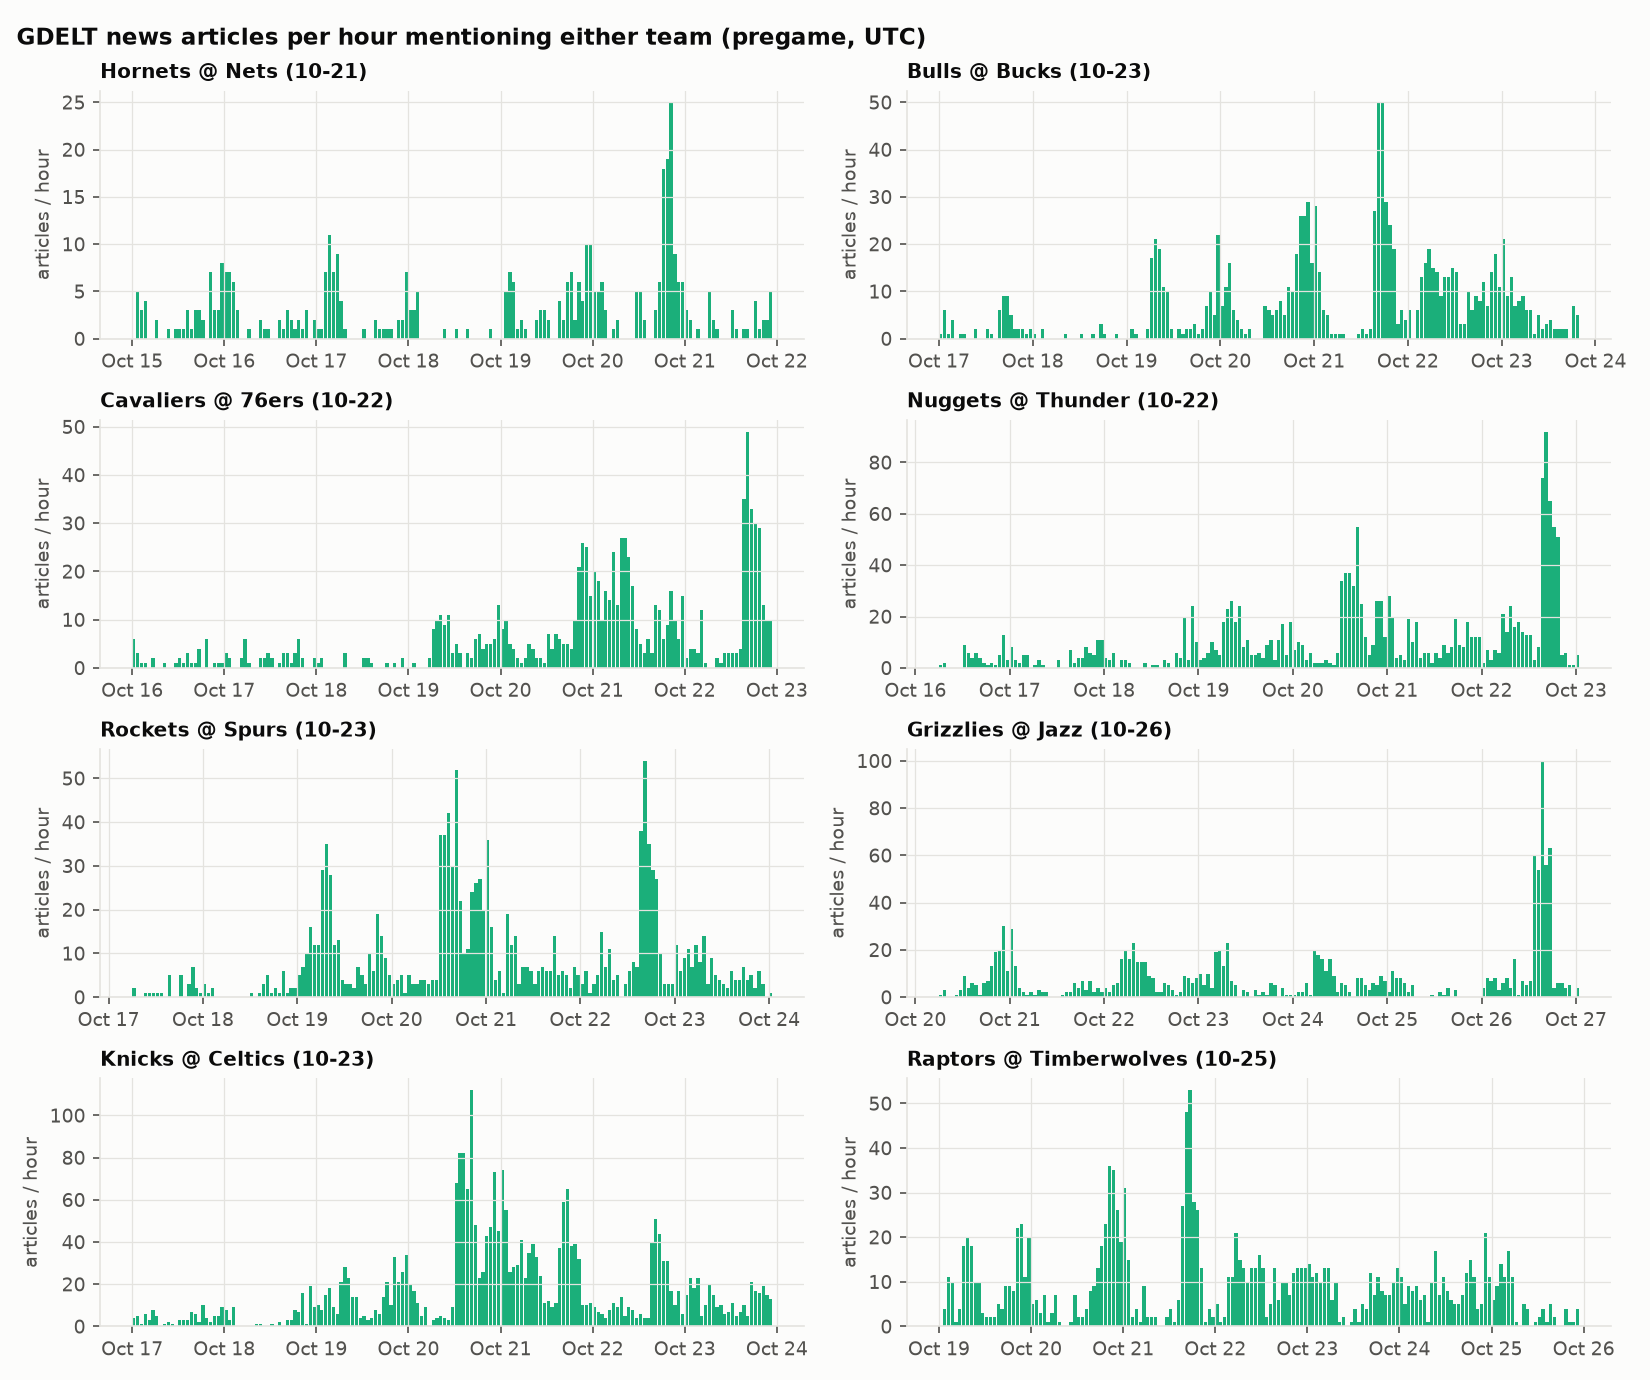

fig4_attention_vs_next_hour.png


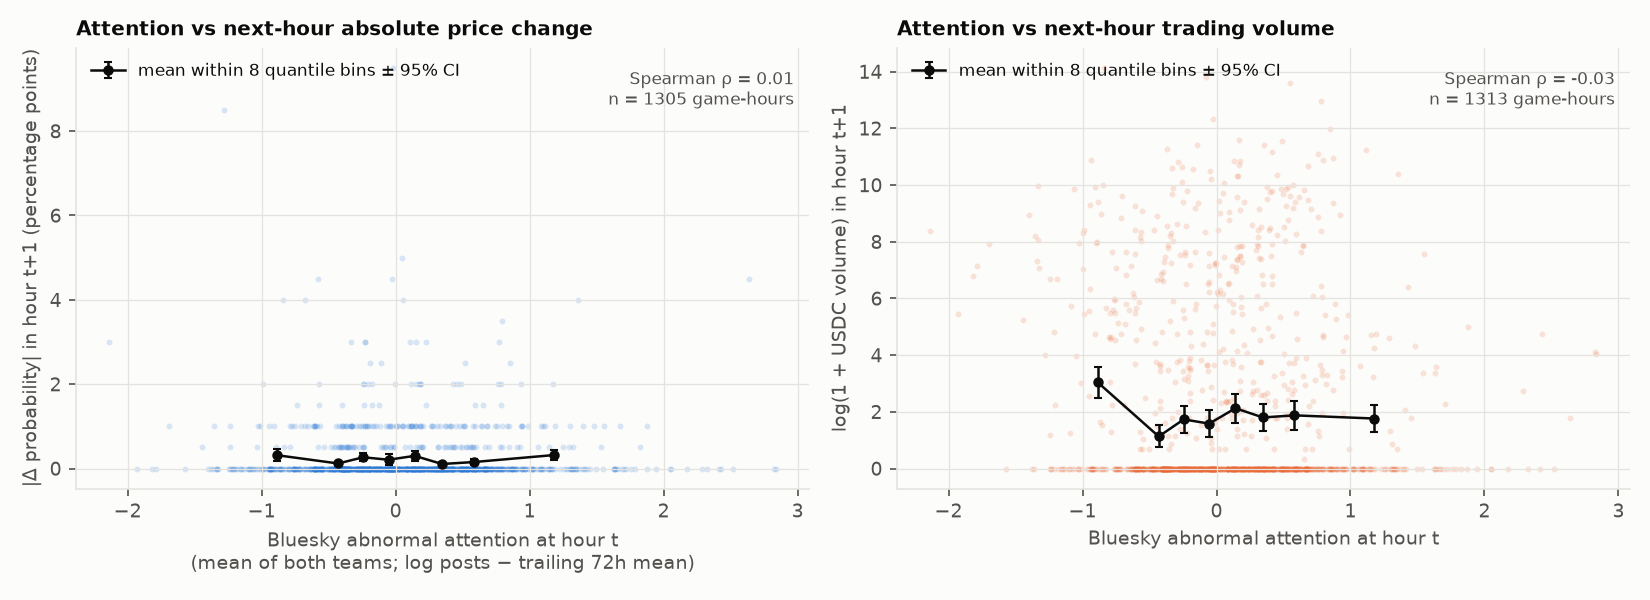

fig5_data_coverage.png


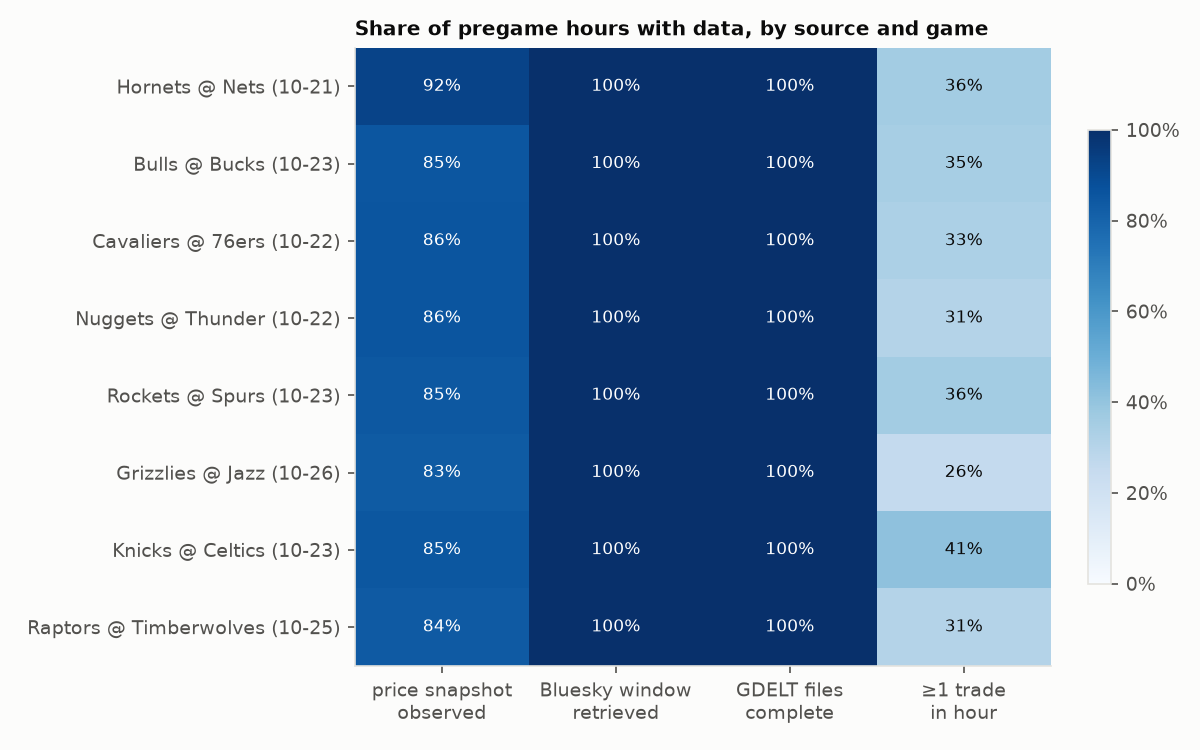

fig6_model_comparison.png


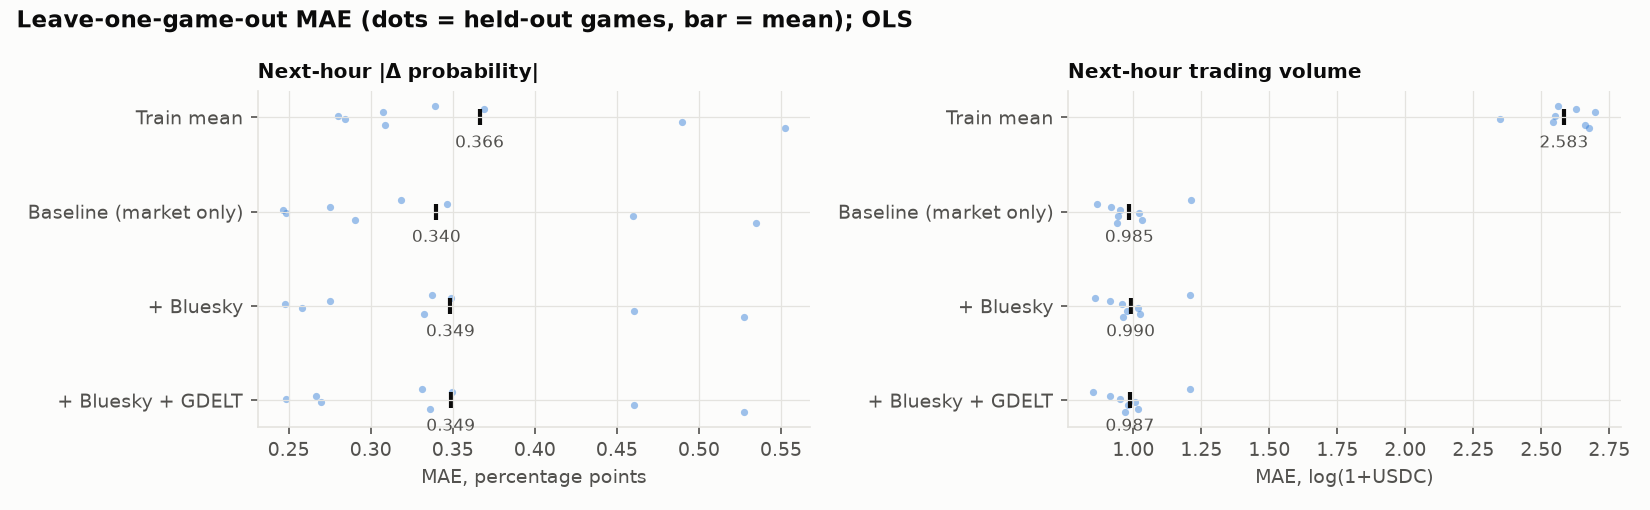

In [9]:
from IPython.display import Image, display
for f in sorted((PROJECT / "figures").glob("*.png")):
    print(f.name); display(Image(filename=str(f)))

## 6. Baseline vs. enhanced models (leave-one-game-out)
* **Targets:** next-hour |Δ probability| and next-hour log(1 + USDC volume).
* **Baseline features:** current and lagged |Δp|, current and lagged log volume, log hours to game.
* **Enhanced features:** baseline + Bluesky abnormal attention (home, away) + log total posts (+ GDELT articles).
* All specifications use the same rows. Each fold holds out one whole game.

In [10]:
pd.read_csv(P / "model_summary.csv")

,target,estimator,model,mean_mae,mean_rmse,n_test_rows
0,abs_dp_next,ols,baseline,0.003400,0.005850,1289
1,abs_dp_next,ols,enhanced_social,0.003486,0.005891,1289
2,abs_dp_next,ols,enhanced_social_news,0.003488,0.005901,1289
3,abs_dp_next,ols,train_mean,0.003663,0.005981,1289
4,abs_dp_next,ridge,baseline,0.003400,0.005850,1289
5,abs_dp_next,ridge,enhanced_social,0.003486,0.005891,1289
6,abs_dp_next,ridge,enhanced_social_news,0.003488,0.005901,1289
7,abs_dp_next,ridge,train_mean,0.003663,0.005981,1289
8,log_vol_next,ols,baseline,0.985497,1.459962,1289
9,log_vol_next,ols,enhanced_social,0.990129,1.464582,1289


In [11]:
pd.read_csv(P / "model_diffs.csv")

,target,estimator,model,mean_mae_diff_vs_baseline,folds_improved,folds
0,abs_dp_next,ols,enhanced_social,0.000086,1,8
1,abs_dp_next,ridge,enhanced_social,0.000086,1,8
2,log_vol_next,ols,enhanced_social,0.004632,5,8
3,log_vol_next,ridge,enhanced_social,0.004598,5,8
4,abs_dp_next,ols,enhanced_social_news,0.000088,2,8
5,abs_dp_next,ridge,enhanced_social_news,0.000087,2,8
6,log_vol_next,ols,enhanced_social_news,0.001976,5,8
7,log_vol_next,ridge,enhanced_social_news,0.001948,5,8


## 7. Unit tests (synthetic fixtures; logic only)

In [12]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], capture_output=True, text=True)
print(r.stdout[-2000:])

.........                                                                [100%]
9 passed in 1.36s

